# Exp 3 — Two-Phase Training (Freeze → Unfreeze) — Improved

**Changes from original:**
1. Increased Phase 1 epochs (5 → 12) so head converges properly
2. Raised learning rates (were too conservative)
3. Added class-weighted `alpha` to FocalLoss for severe class imbalance
4. Added linear warmup scheduler for Phase 2
5. Increased Phase 2 epochs (15 → 25) with early stopping safety net


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path().resolve()))  # so 'from utils import *' works
from utils import *
print("utils loaded ✓")

/scratch/AML_G14_CW/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


utils.py loaded — device=cuda, train=24588, val=5269, test=5269
utils loaded ✓


In [2]:
EXP_DIR   = ROOT / 'outputs' / 'swinv2_small_exp3'
CKPT_DIR_E = EXP_DIR / 'checkpoints'
FIG_DIR_E  = EXP_DIR / 'figures'
for d in (CKPT_DIR_E, FIG_DIR_E): d.mkdir(parents=True, exist_ok=True)
CKPT_P1   = CKPT_DIR_E / 'exp3_phase1_best.pt'
CKPT_PATH = CKPT_DIR_E / 'exp3_best.pt'

# ── Tuned hyperparameters ──────────────────────────────────────────────────────
PHASE1_EPOCHS = 12          # Was 5  → give head time to converge
PHASE2_EPOCHS = 25          # Was 15 → more room with warmup + early stopping

PHASE1_HEAD_LR = 3e-4       # Was 1e-4 → faster head convergence in Phase 1
PHASE2_HEAD_LR = 3e-4       # Was 1e-5 → was far too low
PHASE2_BACK_LR = 3e-5       # Was 1e-6 → 0.1× ratio to head LR
GRAD_CLIP      = 1.0

In [3]:
train_ds    = DRDataset(train_df, TRAIN_DIR, transform=enhanced_train_transform)
val_ds      = DRDataset(val_df,   VAL_DIR,   transform=val_transform)
test_ds     = DRDataset(test_df,  TEST_LABELS_DIR, transform=val_transform)
t_loader    = make_loader(train_ds, sampler=wrs_sampler)
v_loader    = make_val_loader(val_ds)
test_loader = make_val_loader(test_ds)

In [4]:
# ── Class-weighted Focal Loss ──────────────────────────────────────────────────
# Compute inverse-frequency weights so minority classes (Mild, Severe,
# Proliferative) get more loss contribution
import numpy as np

class_counts = train_df['level'].value_counts().sort_index().values.astype(float)
inv_freq     = 1.0 / class_counts
alpha_weights = inv_freq / inv_freq.sum()            # normalise to sum=1
alpha_tensor  = torch.tensor(alpha_weights, dtype=torch.float32).to(device)

print("Class distribution:", class_counts.astype(int))
print("Alpha weights:     ", np.round(alpha_weights, 4))

Class distribution: [18067  1710  3704   611   496]
Alpha weights:      [0.0121 0.1282 0.0592 0.3587 0.4419]


In [5]:
# ── Phase 1: freeze backbone, train head only ─────────────────────────────────
set_seed()
model     = build_swin_model(pretrained=True).to(device)
criterion = FocalLoss(alpha=alpha_tensor, gamma=2.0)   # ← class-weighted
scaler    = torch.amp.GradScaler('cuda', enabled=use_amp)

for name, param in model.named_parameters():
    param.requires_grad = ('custom_head' in name)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Phase 1: {trainable:,} trainable params (custom_head only)')

optimizer  = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=PHASE1_HEAD_LR, weight_decay=WEIGHT_DECAY)
scheduler1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=PHASE1_EPOCHS)

history_p1, _ = train_loop(model, criterion, optimizer, scheduler1, scaler,
                             t_loader, v_loader, CKPT_P1, epochs=PHASE1_EPOCHS)
print('Phase 1 complete.')

Downloaded and loaded.
SwinV2-Small | 49.0M params
Phase 1: 5,381 trainable params (custom_head only)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.0142   0.1545     0.0031   0.0306  ★


2            0.0119   0.2099     0.0027   0.0424  ★


3            0.0112   0.2199     0.0029   0.0336


4            0.0109   0.2417     0.0025   0.0549  ★


...

8            0.0108   0.2353     0.0025   0.0685  ★


9            0.0105   0.2454     0.0025   0.0486


10           0.0105   0.2536     0.0025   0.0604


11           0.0106   0.2537     0.0025   0.0559


12           0.0104   0.2653     0.0025   0.0512

Best val κ = 0.0685
Phase 1 complete.


In [6]:
# ── Phase 2: unfreeze all, layer-wise LR, warmup + cosine ──────────────────────
from torch.optim.lr_scheduler import SequentialLR, LinearLR, CosineAnnealingLR

for param in model.parameters():
    param.requires_grad = True
print(f'Phase 2: {sum(p.numel() for p in model.parameters()):,} trainable params (all)')

ckpt_p1 = torch.load(CKPT_P1, map_location=device, weights_only=False)
model.load_state_dict(ckpt_p1['model_state'])
print(f'Loaded Phase 1 best (epoch {ckpt_p1["epoch"]}, κ={ckpt_p1["val_kappa"]:.4f})')

bp = [p for n,p in model.named_parameters() if 'custom_head' not in n and p.requires_grad]
hp = [p for n,p in model.named_parameters() if 'custom_head'     in n and p.requires_grad]
optimizer  = torch.optim.AdamW(
    [{'params':bp,'lr':PHASE2_BACK_LR},{'params':hp,'lr':PHASE2_HEAD_LR}],
    weight_decay=WEIGHT_DECAY)

# Warmup for 3 epochs then cosine decay for the rest
WARMUP_EPOCHS = 3
warmup_sched  = LinearLR(optimizer, start_factor=0.1, total_iters=WARMUP_EPOCHS)
cosine_sched  = CosineAnnealingLR(optimizer, T_max=PHASE2_EPOCHS - WARMUP_EPOCHS)
scheduler2    = SequentialLR(optimizer, [warmup_sched, cosine_sched],
                             milestones=[WARMUP_EPOCHS])

history_p2, best_kappa = train_loop(model, criterion, optimizer, scheduler2, scaler,
                                     t_loader, v_loader, CKPT_PATH, epochs=PHASE2_EPOCHS)
print(f'Phase 2 complete. Best κ = {best_kappa:.4f}')

Phase 2: 48,964,799 trainable params (all)
Loaded Phase 1 best (epoch 8, κ=0.0685)
Epoch       Tr Loss     Tr κ   Val Loss    Val κ
────────────────────────────────────────────────────


1            0.0097   0.3439     0.0023   0.1203  ★


2            0.0082   0.4409     0.0022   0.1702  ★


3            0.0061   0.4926     0.0027   0.1579


4            0.0047   0.5281     0.0028   0.3219  ★


...

8            0.0019   0.6911     0.0082   0.3157


9            0.0018   0.7196     0.0069   0.2892


10           0.0015   0.7349     0.0085   0.3339


11           0.0012   0.7510     0.0098   0.3368


12           0.0011   0.7593     0.0093   0.2624
Early stopping at epoch 12.

Best val κ = 0.3544
Phase 2 complete. Best κ = 0.3544


In [29]:
import torch
import gc

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

print("CUDA memory cleared")

print(torch.cuda.memory_allocated() / 1024**3, "GB allocated")
print(torch.cuda.memory_reserved() / 1024**3, "GB reserved")

CUDA memory cleared
6.708644390106201 GB allocated
7.017578125 GB reserved


Random init.
SwinV2-Small | 49.0M params
Loaded exp3_best.pt  (epoch 6, κ=0.3544)


/scratch/AML_G14_CW/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/scratch/AML_G14_CW/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/scratch/AML_G14_CW/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.sh


Exp3 — Test Set:
               precision    recall  f1-score   support

        No DR      0.000     0.000     0.000      3872
         Mild      0.077     0.913     0.142       366
     Moderate      0.400     0.003     0.005       794
       Severe      0.164     0.817     0.274       131
Proliferative      0.313     0.783     0.447       106

     accuracy                          0.100      5269
    macro avg      0.191     0.503     0.174      5269
 weighted avg      0.076     0.100     0.026      5269

QWK: 0.3763


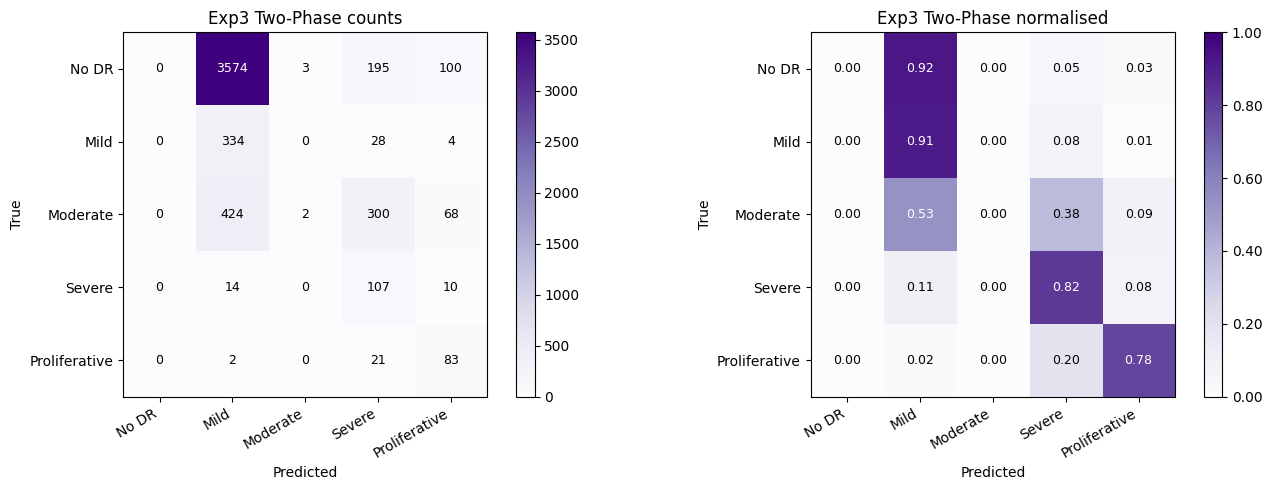

Exp3 QWK: 0.3763


In [31]:
y_true, y_pred = evaluate(model, criterion, optimizer, scaler,
                           test_loader, CKPT_PATH, 'Exp3')
plot_confusion(y_true, y_pred, 'Exp3 Two-Phase', FIG_DIR_E / 'exp3_confusion.png', cmap='Purples')

import json as _json
results = {'qwk': cohen_kappa_score(y_true, y_pred, weights='quadratic'),
           'macro_f1': f1_score(y_true, y_pred, average='macro'),
           'f1_per': f1_score(y_true, y_pred, average=None).tolist(),
           'history_p1': history_p1, 'history_p2': history_p2}
with open(EXP_DIR / 'exp3_results.json', 'w') as f:
    _json.dump(results, f, indent=2)
print(f"Exp3 QWK: {results['qwk']:.4f}")